# Visualizing the VisDrone50 - YOLO11m model

András Farkas, K12445535

In [1]:
!pip install -q ultralytics huggingface_hub

In [2]:
from google.colab import drive
import os
from ultralytics import settings, YOLO
from huggingface_hub import hf_hub_download

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/datasets', exist_ok=True)

Mounted at /content/drive


In [4]:
settings.update({'datasets_dir': '/content/drive/MyDrive/datasets'})

In [5]:
weights = hf_hub_download("dronefreak/visdrone-yolo11m", "best.pt")
model = YOLO(weights)

metrics_val = model.val(
    data="VisDrone.yaml",
    split="val",
    imgsz=1280, #original training size
    batch=16,
    plots=True
)

print(metrics_val.box.map50)    # mAP@50
print(metrics_val.box.map)      # mAP@50-95
print(metrics_val.box.mp)       # precision
print(metrics_val.box.mr)       # recall

best.pt: reconstructing file:   0%|          |  0.00B / 40.6MB            

best.pt: downloading bytes:           |  0.00B            

Ultralytics 8.4.210 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11m summary (fused): 125 layers, 20,038,513 parameters, 0 gradients, 67.8 GFLOPs

WARNING ⚠️ Dataset 'VisDrone.yaml' images not found, missing path '/content/datasets/VisDrone/images/val'
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-val.zip to /content/datasets/VisDrone/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 108.7files/s 10.1s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-test-dev.zip to /content/datasets/VisDrone/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 143.7files/s 22.4s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-train.zip to /content/datasets/VisDrone/VisDrone2019-DET-train...: 100% ━━━━━━━━━━━━ 12945/12945 535.9files/s 24.2s
Converting train: ━━━━━━━━━━━━ 6471 1.4Kit/s 5.0s
Converting val: ━━━━━━━━━━━━ 548 949.4it/s 0.6s
Converting test: ━━━━━━━━━━━━ 1610 1.6Kit/s 1.0s
Dataset download success ✅ (63.6s), saved to /content/datasets

val:

In [32]:
metrics_test = model.val(
    data="VisDrone.yaml",
    split="test",
    imgsz=1280,
    batch=16,
    plots=True
)

print(metrics_test.box.map50)    # mAP@50
print(metrics_test.box.map)      # mAP@50-95
print(metrics_test.box.mp)       # precision
print(metrics_test.box.mr)       # recall

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,038,513 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2052.5±775.7 MB/s, size: 177.0 KB)
val: Scanning /content/datasets/VisDrone/labels/test.cache... 1610 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1610/1610 259.7Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 461 objects (test=461), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=461 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 101/101 1.5s/it 2:32
                   all       1610      75102      0.593      0.483      0.481      0.286
            pedestrian       1197      21006      0.663      0.467      0.

## Metrics over classes

In [8]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

In [15]:
names = ['pedestrian','people','bicycle','car','van','truck',
         'tricycle','awning-tricycle','bus','motor']

root = Path("/content/datasets/VisDrone/labels")

counts_by_split = {}

for split in ["train", "val", "test"]:
    folder = root / split
    if not folder.exists():
        continue
    counts = Counter()
    for f in folder.glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1
    counts_by_split[split] = [counts[i] for i in range(len(names))]

train_counts = counts_by_split["train"]
val_counts   = counts_by_split.get("val")
test_counts  = counts_by_split.get("test")

In [16]:
print(train_counts)
print(val_counts)
print(test_counts)

[79337, 27059, 10480, 144867, 24956, 12875, 4812, 3246, 5926, 29647]
[8844, 5125, 1287, 14064, 1975, 750, 1045, 532, 251, 4886]
[21006, 6376, 1302, 28074, 5771, 2659, 530, 599, 2940, 5845]


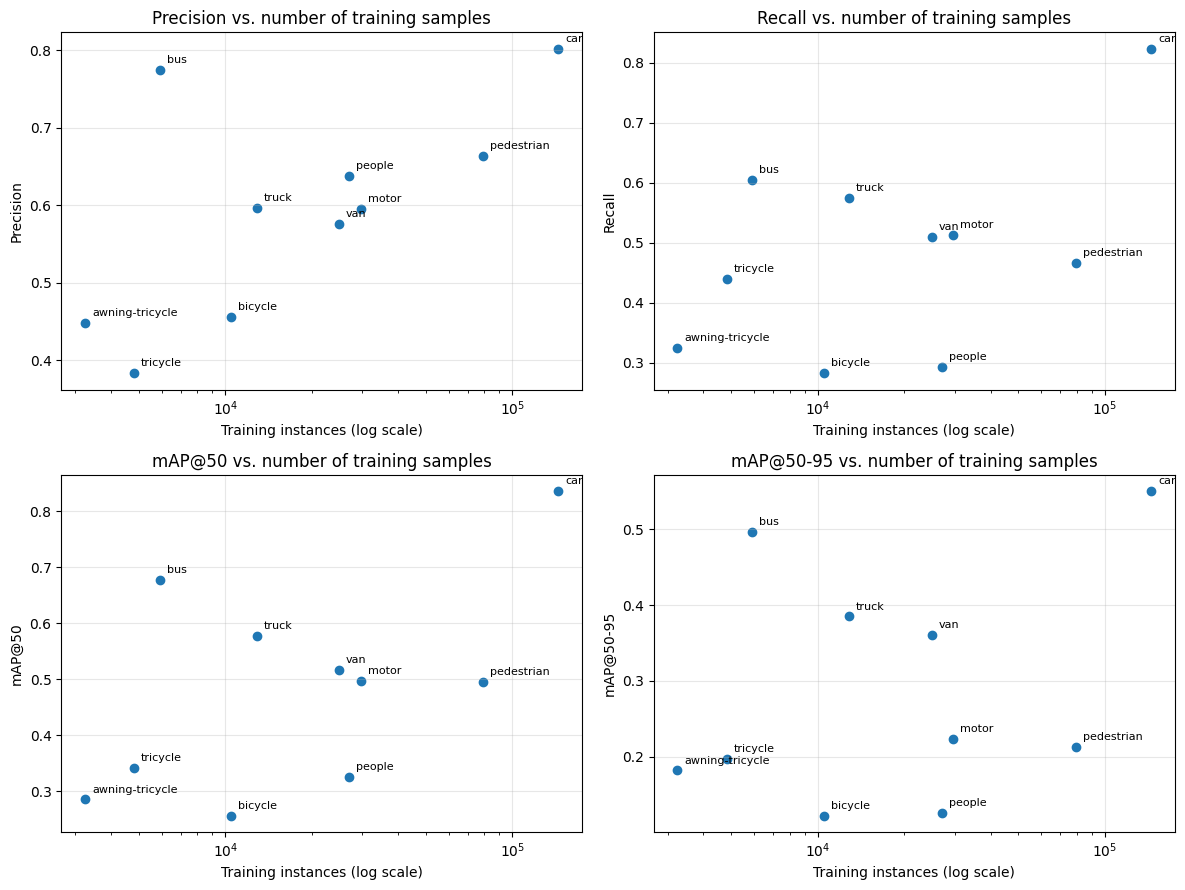

In [37]:
idx = metrics_test.box.ap_class_index

x = np.array([train_counts[i] for i in idx])
labels = [names[i] for i in idx]

panels = {
    "Precision":  metrics_test.box.p,       #TP / (TP + FP)
    "Recall":     metrics_test.box.r,       #TP / (TP + FN)
    "mAP@50":     metrics_test.box.ap50,
    "mAP@50-95":  metrics_test.box.ap,
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (title, y) in zip(axes.ravel(), panels.items()):
    ax.scatter(x, y)
    for xi, yi, lab in zip(x, y, labels):
        ax.annotate(lab, (xi, yi), textcoords="offset points",
                    xytext=(5, 5), fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("Training instances (log scale)")
    ax.set_ylabel(title)
    ax.set_title(f"{title} vs. number of training samples")
    ax.grid(alpha=0.3)


plt.tight_layout()
plt.savefig("metrics.png", dpi=200)
plt.show()